# 05 — Evaluación final: calidad de datos, comparación equivalente de modelos y significancia
**CRISP-DM: Evaluación** · Etapa final · Título provisional: *Predicción del precio de productos agrícolas en mercados de El Salvador*

Este notebook **no recalcula** los modelos: lee los resultados que generan los scripts de `scripts/` (carpeta `reports/etapa3/`) y los presenta con tablas y gráficos. Así se ejecuta en segundos y las cifras coinciden con las del informe.

Para generar los resultados desde cero, con el entorno virtual activo y desde la raíz del repositorio:

```bash
python scripts/run_all.py
```

**Secciones:** 1) datos y calidad · 2) nulos y valores atípicos · 3) referencias ingenuas · 4) resultados por producto · 5) ensamble · 6) significancia e intervalos · 7) variables externas (lluvia) · 8) LSTM · 9) conclusiones y limitaciones.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")

RAIZ = Path.cwd().parent                      # el notebook se ejecuta desde notebooks/
sys.path.append(str(RAIZ / "src"))
from prediccion_precios import config

ET = RAIZ / "reports" / "etapa3"              # resultados de los scripts
FIG = RAIZ / "reports" / "figures"            # figuras para el informe
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid", context="notebook")
ORDEN = ["ARROZ", "MAÍZ", "FRIJOL", "NARANJA", "TOMATE"]


def leer(nombre):
    ruta = ET / nombre
    if not ruta.exists():
        raise FileNotFoundError(f"Falta {ruta}. Genera los resultados con: python scripts/run_all.py")
    return pd.read_csv(ruta)


def guardar(fig, nombre):
    fig.savefig(FIG / nombre, dpi=200, bbox_inches="tight")
    print("Figura guardada en", FIG / nombre)

## 1. Datos y calidad de la información
La variable objetivo (precio diario del MAG) limita todo el estudio: las demás fuentes llegan a 2024 o más, pero sin precios no pueden aprovecharse.

In [2]:
cob = leer("cobertura_fuentes.csv")
display(cob)

,fuente,inicio,fin,frecuencia,nota
0,Precios MAG (consolidado),2021-05-07,2024-06-26,diaria (lun-vie),variable objetivo; limita todo el proyecto
1,Combustibles,2010-12-28,2026-05-11,diaria,'Diesel' regular = 0 en 2 672 filas (se sustit...
2,Precipitación diaria,2021-01-01,2024-12-31,diaria,promedio de 83-100 estaciones por día
3,Lluvia mensual,Enero 2021,Diciembre 2024,mensual,NaN
4,FAOSTAT producción,2021,2024,anual,2023-2024: valores imputados/estimados/no ofic...


In [3]:
aud = leer("auditoria_precios.csv").set_index("producto").loc[ORDEN]
display(aud[["registros", "registros_nd", "dias_con_dato", "primer_dia", "ultimo_dia",
             "semanas_con_dato", "semanas_con_1_o_2_dias"]])
sem = leer("semanas_sin_dato.csv")
print("Semanas sin ningún precio (cierre en domingo) y productos afectados:")
display(sem.groupby("semana_cierre").size().rename("productos_sin_dato").to_frame())

,registros,registros_nd,dias_con_dato,primer_dia,ultimo_dia,semanas_con_dato,semanas_con_1_o_2_dias
producto,,,,,,,
ARROZ,728,2,720,2021-05-07,2024-06-26,157,2
MAÍZ,728,2,720,2021-05-07,2024-06-26,157,2
FRIJOL,728,2,720,2021-05-07,2024-06-26,157,2
NARANJA,728,3,719,2021-05-07,2024-06-26,157,2
TOMATE,728,2,720,2021-05-07,2024-06-26,157,2


Semanas sin ningún precio (cierre en domingo) y productos afectados:


,productos_sin_dato
semana_cierre,
2021-08-08,5
2022-01-02,5
2022-04-17,5
2022-08-07,5
2023-01-01,5
2023-04-09,5
2023-12-31,5
2024-03-31,5


### 1.1 Precios repetidos: el caso de la naranja

Figura guardada en c:\Users\irmal\OneDrive\Escritorio\ML\prediccion_precios_agricolas\reports\figures\etapa3_precios_repetidos.png


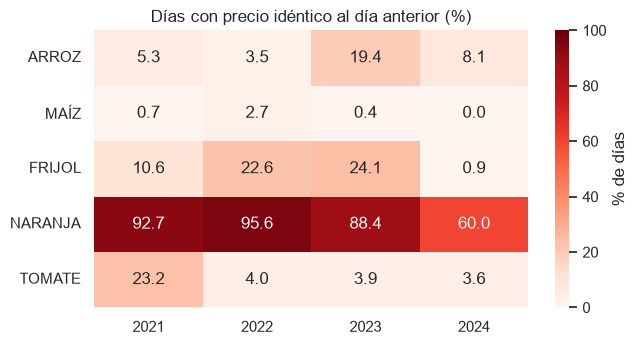

In [4]:
cols = {"pct_identico_2021": "2021", "pct_identico_2022": "2022", "pct_identico_2023": "2023", "pct_identico_2024": "2024"}
rep = aud[list(cols)].rename(columns=cols)
fig, ax = plt.subplots(figsize=(7, 3.6))
sns.heatmap(rep, annot=True, fmt=".1f", cmap="Reds", vmin=0, vmax=100, cbar_kws={"label": "% de días"}, ax=ax)
ax.set_title("Días con precio idéntico al día anterior (%)"); ax.set_ylabel(""); ax.set_xlabel("")
guardar(fig, "etapa3_precios_repetidos.png"); plt.show()

### 1.2 Recorte por IQR del pipeline original
El recorte original (Q1 − 1.5·IQR, Q3 + 1.5·IQR con toda la muestra) solo afecta al **tomate**.

In [5]:
display(aud[["limite_IQR_superior", "precio_max_crudo", "dias_recortados_IQR"]])

,limite_IQR_superior,precio_max_crudo,dias_recortados_IQR
producto,,,
ARROZ,55.61,46.55,0
MAÍZ,42.11,30.84,0
FRIJOL,148.07,115.00,0
NARANJA,20.00,18.00,0
TOMATE,34.03,37.73,13


## 2. Nulos y valores atípicos: ¿cambia la conclusión?
Cuatro variantes del tratamiento, evaluadas contra el precio semanal **crudo** en las mismas semanas de prueba: **V0** original, **V1** sin recorte, **V2** causal sin recorte y **V3** causal con recorte calculado solo con entrenamiento.

Global                        Tomate                 
modelo   persistencia regresion_lineal persistencia regresion_lineal
variante                                                            
V0               4.70             6.01        15.85            18.16
V1               4.72             6.03        15.95            18.31
V2               4.91             6.54        16.51            19.93
V3               4.79             6.33        15.94            19.04

Figura guardada en c:\Users\irmal\OneDrive\Escritorio\ML\prediccion_precios_agricolas\reports\figures\etapa3_sensibilidad_nulos.png


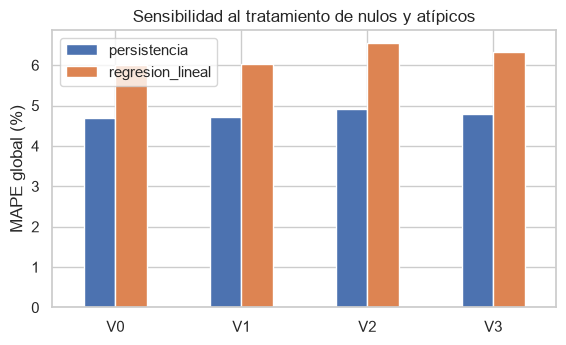

Diferencia máxima entre variantes (puntos): persistencia 0.21, regresión lineal 0.52


In [6]:
sen = leer("sensibilidad_nulos.csv")
obs = sen[sen.subconjunto == "real_observado"]
glob = obs[obs.producto == "GLOBAL"].pivot(index="variante", columns="modelo", values="MAPE_%")
tom = obs[obs.producto == "TOMATE"].pivot(index="variante", columns="modelo", values="MAPE_%")
display(pd.concat({"Global": glob, "Tomate": tom}, axis=1).round(2))

fig, ax = plt.subplots(figsize=(6.5, 3.6))
glob.plot(kind="bar", ax=ax, rot=0, color=["#4C72B0", "#DD8452"])
ax.set_ylabel("MAPE global (%)"); ax.set_xlabel(""); ax.set_title("Sensibilidad al tratamiento de nulos y atípicos")
ax.legend(title="")
guardar(fig, "etapa3_sensibilidad_nulos.png"); plt.show()
print("Diferencia máxima entre variantes (puntos): persistencia %.2f, regresión lineal %.2f"
      % (glob["persistencia"].max() - glob["persistencia"].min(),
         glob["regresion_lineal"].max() - glob["regresion_lineal"].min()))

## 3. Referencias ingenuas y series de tiempo clásicas
Un MAPE solo es «bueno» respecto a una referencia. Sobre las 157 filas de prueba del proyecto:

horizonte,1,2,4,8
metodo,,,,
persistencia,4.49,6.76,10.48,16.24
ets_amortiguado,4.50,6.76,10.86,16.90
deriva,4.57,6.93,10.93,17.74
arima_p10,4.64,6.96,11.07,17.68
media_movil_4,6.87,8.96,12.49,17.04
estacional_52,16.87,16.87,16.87,16.87


Figura guardada en c:\Users\irmal\OneDrive\Escritorio\ML\prediccion_precios_agricolas\reports\figures\etapa3_baselines_horizonte.png


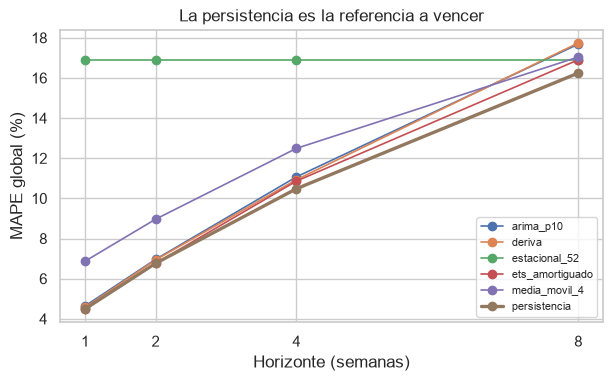

In [7]:
m = leer("metricas_baselines.csv")
mg = m[m.producto == "GLOBAL"].pivot(index="metodo", columns="horizonte", values="MAPE_%").round(2)
display(mg.sort_values(1))
fig, ax = plt.subplots(figsize=(7, 3.8))
for met, fila in mg.iterrows():
    ax.plot(fila.index, fila.values, marker="o", label=met, lw=2.4 if met == "persistencia" else 1.2)
ax.set_xlabel("Horizonte (semanas)"); ax.set_ylabel("MAPE global (%)"); ax.set_xticks([1, 2, 4, 8])
ax.set_title("La persistencia es la referencia a vencer"); ax.legend(fontsize=8)
guardar(fig, "etapa3_baselines_horizonte.png"); plt.show()

## 4. Resultados por producto y horizonte
El error de la persistencia cambia por casi dos órdenes de magnitud entre productos, por eso se presenta **por producto**.

In [8]:
t = leer("tabla_por_producto.csv")
pers = t[t.modelo == "persistencia"].pivot(index="producto", columns="horizonte", values="MAPE").loc[ORDEN].round(2)
display(pers.rename_axis("MAPE (%) de la persistencia"))

horizonte,1,2,4,8
MAPE (%) de la persistencia,,,,
ARROZ,0.22,0.22,0.14,0.22
MAÍZ,1.53,2.84,5.09,8.19
FRIJOL,1.79,3.41,5.87,7.88
NARANJA,4.51,7.08,9.92,16.76
TOMATE,16.37,20.69,33.28,49.28


Figura guardada en c:\Users\irmal\OneDrive\Escritorio\ML\prediccion_precios_agricolas\reports\figures\etapa3_razon_por_producto.png


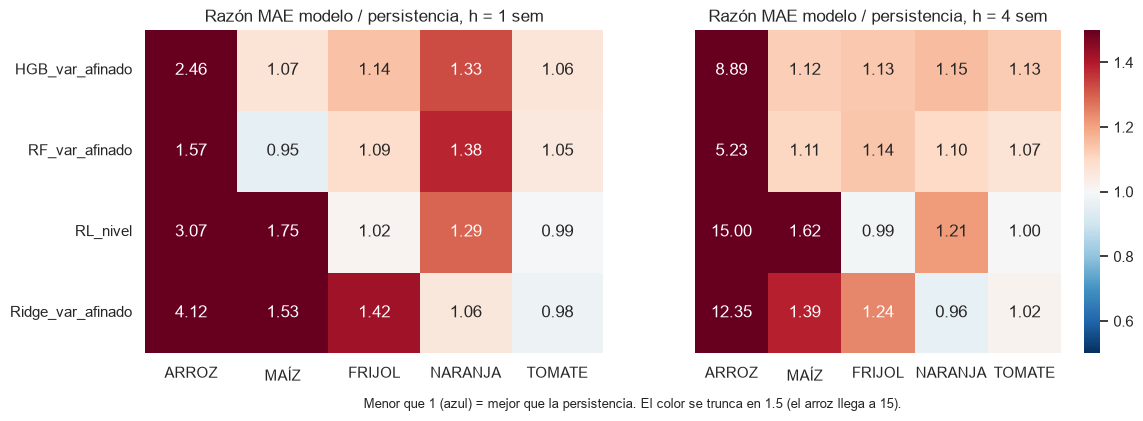

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, h in zip(axes, (1, 4)):
    r = (t[(t.horizonte == h) & (t.modelo != "persistencia")]
         .pivot(index="modelo", columns="producto", values="razon_vs_persistencia")[ORDEN])
    sns.heatmap(r.clip(upper=3), annot=r.map(lambda v: f"{v:.2f}"), fmt="", cmap="RdBu_r", center=1, vmin=0.5, vmax=1.5,
                cbar=ax is axes[1], ax=ax)
    ax.set_title(f"Razón MAE modelo / persistencia, h = {h} sem"); ax.set_ylabel(""); ax.set_xlabel("")
fig.text(0.5, -0.02, "Menor que 1 (azul) = mejor que la persistencia. El color se trunca en 1.5 (el arroz llega a 15).",
         ha="center", fontsize=9)
guardar(fig, "etapa3_razon_por_producto.png"); plt.show()

In [10]:
sin = t[(t.producto != "ARROZ") & (t.modelo != "persistencia")]
prom = sin.groupby(["modelo", "horizonte"]).razon_vs_persistencia.mean().unstack().round(3)
display(prom.rename_axis("Razón promedio entre productos (sin arroz)"))

horizonte,1,2,4,8
Razón promedio entre productos (sin arroz),,,,
HGB_var_afinado,1.150,1.154,1.135,1.167
RF_var_afinado,1.120,1.060,1.104,1.188
RL_nivel,1.262,1.223,1.206,1.163
Ridge_var_afinado,1.245,1.222,1.152,1.178


## 5. Ensamble contraído hacia la persistencia
Pronóstico = p<sub>t</sub> · (1 + w · r), con r el promedio de las variaciones que predicen Ridge, Random Forest y Gradient Boosting, y w ∈ {0, .25, .5, .75, 1} elegido por producto y horizonte con validación previa a la prueba (w = 0 es la persistencia).

In [11]:
ens = leer("ensamble_resumen.csv")
e = ens[ens.modelo == "ensamble_contraido"].pivot(index="producto", columns="horizonte", values="razon_vs_persistencia").loc[ORDEN].round(3)
display(e.rename_axis("Razón MAE ensamble / persistencia"))
w = leer("ensamble_pesos.csv").pivot(index="producto", columns="horizonte", values="w").loc[ORDEN]
display(w.rename_axis("Peso w elegido (0 = persistencia)"))

horizonte,1,2,4,8
Razón MAE ensamble / persistencia,,,,
ARROZ,1.000,1.000,1.000,1.000
MAÍZ,1.000,1.000,1.000,1.000
FRIJOL,1.050,1.049,1.066,1.154
NARANJA,1.000,1.000,1.000,0.979
TOMATE,0.999,1.038,1.011,1.019


horizonte,1,2,4,8
Peso w elegido (0 = persistencia),,,,
ARROZ,0.00,0.00,0.00,0.00
MAÍZ,0.00,0.00,0.00,0.00
FRIJOL,0.50,0.50,0.50,0.75
NARANJA,0.00,0.00,0.00,1.00
TOMATE,0.25,0.75,0.25,0.25


## 6. Significancia estadística e intervalos de predicción
Prueba de Diebold-Mariano (error absoluto escalado por producto, 28 semanas, Newey-West con corrección de Harvey et al.): H0 = igual precisión que la persistencia.

In [12]:
dm = leer("diebold_mariano.csv")
p = dm.pivot(index="modelo", columns="horizonte", values="p_valor")
display(p.round(3).rename_axis("Valor p (frente a la persistencia)"))
dif = dm.pivot(index="modelo", columns="horizonte", values="dif_media_escalada").round(2)
display(dif.rename_axis("Diferencia media escalada (> 0 = el modelo es peor)"))

horizonte,1,2,4,8
Valor p (frente a la persistencia),,,,
HGB_var_afinado,0.000,0.000,0.000,0.016
RF_var_afinado,0.010,0.037,0.017,0.008
RL_nivel,0.000,0.000,0.002,0.000
Ridge_var_afinado,0.000,0.000,0.001,0.008
ensamble_contraido,0.253,0.311,0.181,0.426


horizonte,1,2,4,8
Diferencia media escalada (> 0 = el modelo es peor),,,,
HGB_var_afinado,0.41,0.49,1.69,2.24
RF_var_afinado,0.21,0.24,0.93,1.64
RL_nivel,0.62,1.06,2.96,2.64
Ridge_var_afinado,0.82,1.23,2.39,2.81
ensamble_contraido,0.01,0.02,0.02,0.03


Figura guardada en c:\Users\irmal\OneDrive\Escritorio\ML\prediccion_precios_agricolas\reports\figures\etapa3_cobertura_intervalos.png


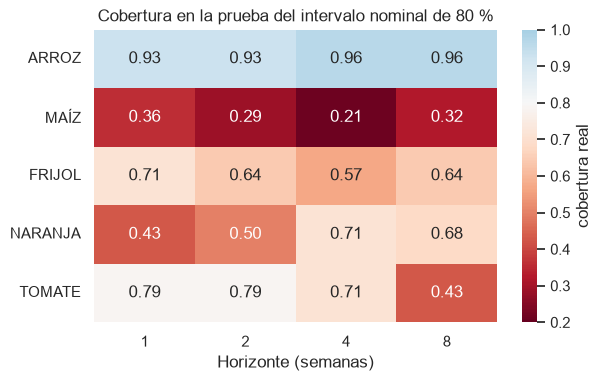

Cobertura media real: {0.8: 0.629, 0.9: 0.734} (nominal 0.8 y 0.9)


In [13]:
iv = leer("intervalos_persistencia.csv")
c80 = iv[iv.nivel_nominal == 0.8].pivot(index="producto", columns="horizonte", values="cobertura_prueba").loc[ORDEN]
fig, ax = plt.subplots(figsize=(6.5, 3.8))
sns.heatmap(c80, annot=True, fmt=".2f", cmap="RdBu", center=0.8, vmin=0.2, vmax=1.0, ax=ax,
            cbar_kws={"label": "cobertura real"})
ax.set_title("Cobertura en la prueba del intervalo nominal de 80 %"); ax.set_xlabel("Horizonte (semanas)"); ax.set_ylabel("")
guardar(fig, "etapa3_cobertura_intervalos.png"); plt.show()
print("Cobertura media real:", iv.groupby("nivel_nominal").cobertura_prueba.mean().round(3).to_dict(), "(nominal 0.8 y 0.9)")

## 7. Variables externas: ¿aporta la lluvia mensual?
Cuatro conjuntos de variables con los modelos afinados y el mismo protocolo. La variante «mensual del mes en curso» incluye días futuros del mes: es una cota optimista, no utilizable en la práctica.

In [14]:
ll = leer("prueba_lluvia_mensual.csv")
orden_v = ["base", "sin_lluvia", "+mensual_prev", "+mensual_act"]
tabla = (ll[ll.producto != "ARROZ"].groupby(["variante", "modelo"]).razon.mean().unstack(0)[orden_v].round(3))
display(tabla.rename_axis("Razón MAE / persistencia (sin arroz, promedio de horizontes)"))
print("Promedio de todos los modelos:", tabla.mean().round(3).to_dict())

variante,base,sin_lluvia,+mensual_prev,+mensual_act
"Razón MAE / persistencia (sin arroz, promedio de horizontes)",,,,
HGB_var,1.152,1.153,1.155,1.151
RF_var,1.118,1.124,1.119,1.113
RL_nivel,1.214,1.218,1.211,1.233
Ridge_var,1.199,1.202,1.202,1.199


Promedio de todos los modelos: {'base': 1.171, 'sin_lluvia': 1.174, '+mensual_prev': 1.172, '+mensual_act': 1.174}


## 8. LSTM con el mismo protocolo
Disponible solo si se ejecutó `python scripts/a11_lstm.py` (requiere TensorFlow). Las salidas `*_stub.csv` son de una verificación de flujo de datos y **no** corresponden al LSTM.

In [15]:
ruta = ET / "lstm_resumen.csv"
if ruta.exists():
    ls = pd.read_csv(ruta)
    r = ls.pivot(index="producto", columns="horizonte", values="razon_vs_persistencia").loc[ORDEN].round(2)
    display(r.rename_axis("Razón MAE LSTM / persistencia"))
    print("Promedio sin arroz:", ls[ls.producto != "ARROZ"].groupby("horizonte").razon_vs_persistencia.mean().round(3).to_dict())
else:
    print("Aún no hay lstm_resumen.csv. Ejecuta: python scripts/a11_lstm.py --precios data/interim/precios_consolidados.xlsx")

horizonte,1,2,4,8
Razón MAE LSTM / persistencia,,,,
ARROZ,2.84,4.05,7.84,17.71
MAÍZ,1.36,1.35,1.44,1.47
FRIJOL,1.52,1.19,1.48,1.73
NARANJA,1.08,1.07,1.08,0.81
TOMATE,1.01,1.07,0.94,0.91


Promedio sin arroz: {1: 1.242, 2: 1.17, 4: 1.236, 8: 1.228}


## 9. Conclusiones y limitaciones
**Conclusiones**
1. La persistencia es la mejor referencia (MAPE global de 4.49 % a una semana y 16.24 % a ocho) y no la superan ni ETS ni ARIMA.
2. Con afinación equivalente y origen móvil, ningún modelo la supera de forma consistente; Diebold-Mariano los da como significativamente peores.
3. El tratamiento de nulos y atípicos cambia el MAPE en menos de 0.6 puntos: se adopta el causal por rigor, no porque explique el resultado.
4. Un ensamble que corrige la persistencia solo si la validación lo justifica la iguala, pero no la mejora.
5. Ni la lluvia diaria ni la mensual aportan información predictiva.

**Limitaciones:** los precios llegan a junio de 2024; la prueba tiene 28 semanas por producto; los precios de la naranja se repiten en el 87 % de los días; los intervalos empíricos subcubren (63 % frente a 80 % nominal); las fuentes de lluvia no coinciden y la producción de 2023-2024 es imputada o no oficial.